# Phase 2: Exploratory Data Analysis

## Objective
Explore hourly, weekly, and seasonal electricity demand patterns to identify useful features for machine learning models.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Locate project folder
project = Path.cwd()
if not (project / "data_processed").exists():
    project = project.parent

file_path = project / "data_processed" / "pjm_rto_hourly_2021_2025.csv"

df = pd.read_csv(file_path)

# Convert timestamps
df["datetime_beginning_utc"] = pd.to_datetime(
    df["datetime_beginning_utc"], utc=True
)

df["datetime_ept"] = df["datetime_beginning_utc"].dt.tz_convert(
    "America/New_York"
)

# Create time variables for EDA
df["hour"] = df["datetime_ept"].dt.hour
df["day_of_week"] = df["datetime_ept"].dt.dayofweek
df["month"] = df["datetime_ept"].dt.month

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (43824, 8)


,datetime_beginning_utc,datetime_ept,mw,source_year,is_verified,hour,day_of_week,month
0,2021-01-01 05:00:00+00:00,2021-01-01 00:00:00-05:00,81842.644,2021,False,0,4,1
1,2021-01-01 06:00:00+00:00,2021-01-01 01:00:00-05:00,80005.690,2021,False,1,4,1
2,2021-01-01 07:00:00+00:00,2021-01-01 02:00:00-05:00,78940.704,2021,False,2,4,1
3,2021-01-01 08:00:00+00:00,2021-01-01 03:00:00-05:00,78563.968,2021,False,3,4,1
4,2021-01-01 09:00:00+00:00,2021-01-01 04:00:00-05:00,79136.453,2021,False,4,4,1


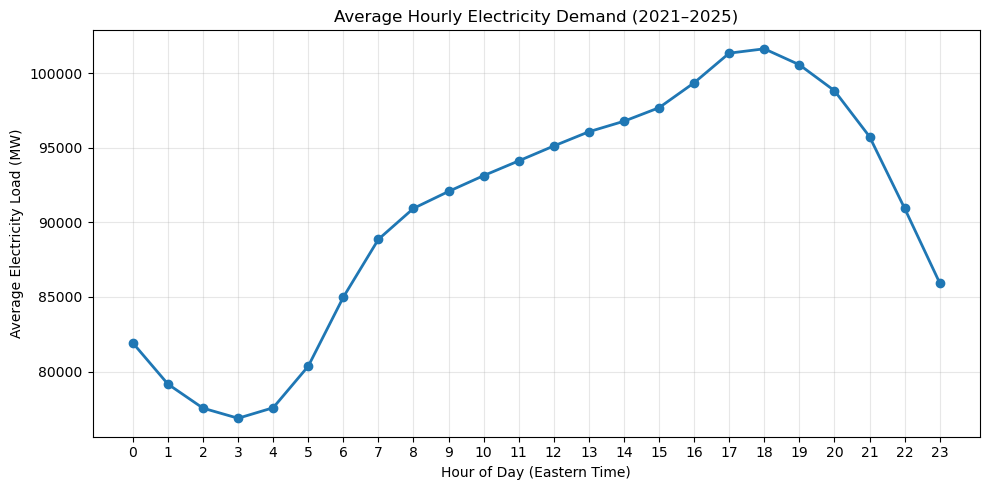

In [ ]:
# Step 2.1: Hourly demand pattern

hourly_avg = df.groupby("hour")["mw"].mean()

plt.figure(figsize=(10, 5))

plt.plot(
    hourly_avg.index,
    hourly_avg.values,
    marker="o",
    linewidth=2
)

plt.title("Average Hourly Electricity Demand (2021–2025)")
plt.xlabel("Hour of Day (Eastern Time)")
plt.ylabel("Average Electricity Load (MW)")
plt.xticks(range(0, 24))
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Hourly Demand Pattern

Average electricity demand follows a clear daily pattern, reaching its lowest level around 3 AM and peaking around 6 PM. Demand rises rapidly in the morning and gradually declines during the evening. This suggests that the hour of day may be an important predictor for electricity demand forecasting

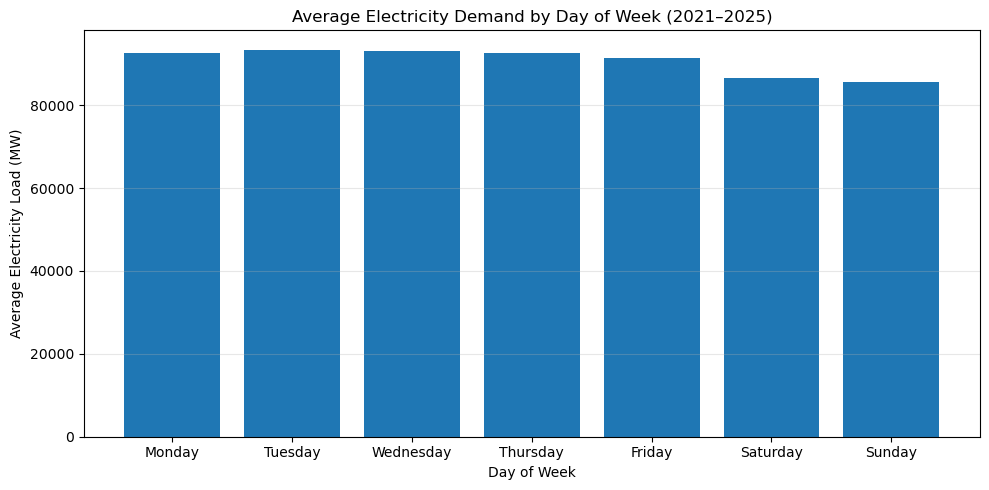

In [3]:
# Step 2.2: Weekly demand patterns

weekly_avg = df.groupby("day_of_week")["mw"].mean()

days = [
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday", "Sunday"
]

plt.figure(figsize=(10, 5))

plt.bar(days, weekly_avg.values)

plt.title("Average Electricity Demand by Day of Week (2021–2025)")
plt.xlabel("Day of Week")
plt.ylabel("Average Electricity Load (MW)")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

Weekly Demand Pattern

Average electricity demand is generally higher on weekdays than on weekends, with Tuesday showing the highest average load and Sunday the lowest. This weekly pattern suggests that day of week and weekend indicators may be useful features for electricity demand forecasting.

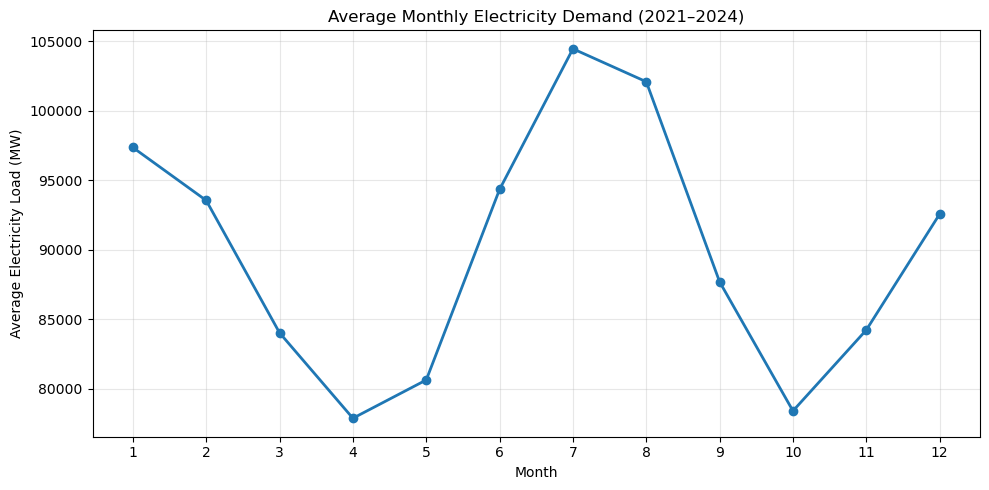

In [4]:
# Step 2.3: Monthly and seasonal demand patterns

# Use development data only (keep 2025 for final testing)
eda_df = df[df["source_year"] <= 2024].copy()

monthly_avg = eda_df.groupby("month")["mw"].mean()

plt.figure(figsize=(10, 5))

plt.plot(
    monthly_avg.index,
    monthly_avg.values,
    marker="o",
    linewidth=2
)

plt.title("Average Monthly Electricity Demand (2021–2024)")
plt.xlabel("Month")
plt.ylabel("Average Electricity Load (MW)")
plt.xticks(range(1, 13))
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Monthly and Seasonal Demand Patterns

Electricity demand shows strong seasonal variation, with the highest average load occurring in July and August and a smaller peak during winter. Demand is generally lowest in spring and fall, particularly in April and October. These patterns suggest that month and season may be useful features for forecasting electricity demand.

,Lag (hours),Autocorrelation
0,1,0.9794
1,2,0.9222
2,3,0.8381
3,6,0.5231
4,12,0.2063
5,24,0.9106
6,48,0.8037
7,72,0.7496
8,168,0.7488
9,336,0.7388


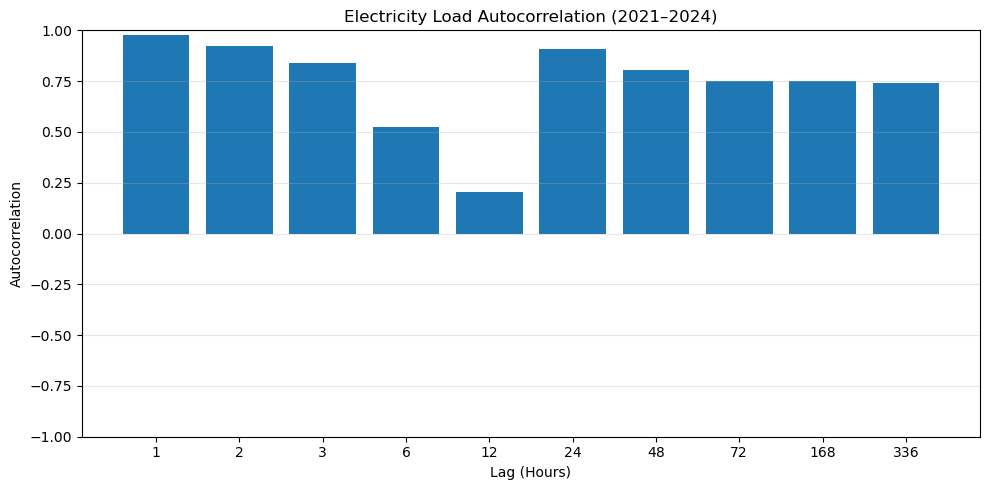

In [5]:
# Step 2.4: Autocorrelation and lag analysis

# Use development data only (2021–2024)
lag_df = (
    df[df["source_year"] <= 2024]
    .sort_values("datetime_beginning_utc")
    .copy()
)

# Calculate autocorrelation at selected lags
lags = [1, 2, 3, 6, 12, 24, 48, 72, 168, 336]

autocorr_values = [
    lag_df["mw"].autocorr(lag=lag)
    for lag in lags
]

lag_results = pd.DataFrame({
    "Lag (hours)": lags,
    "Autocorrelation": autocorr_values
})

display(lag_results.round(4))

# Plot autocorrelation
plt.figure(figsize=(10, 5))

plt.bar(
    lag_results["Lag (hours)"].astype(str),
    lag_results["Autocorrelation"]
)

plt.title("Electricity Load Autocorrelation (2021–2024)")
plt.xlabel("Lag (Hours)")
plt.ylabel("Autocorrelation")
plt.ylim(-1, 1)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

### Autocorrelation and Lag Analysis

Electricity demand shows strong temporal dependence, particularly at lags of 1 hour (0.9794) and 24 hours (0.9106). The correlation at 168 hours (0.7488) also indicates a weekly pattern. These results suggest that historical load features may be useful for forecasting. However, lag features must be constructed using only information available at the forecast origin to avoid data leakage.